<img src="../res/logo.jpg" alt="Volcanicus" width="50%">

# Scene descriptors

A scene (see [scenes.ipynb](scenes.ipynb)) is a grid of 8 directions x 30 distance bins: 240 numbers per date. `scenes_descriptors()` condenses each scene into **five interpretable numbers** that are comparable across dates and volcanoes.

This notebook explains what each descriptor measures, how missing data is handled, and two caveats worth knowing before using them — including a real data problem in the **Kadovar** dataset.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import volcanicus
from volcanicus.constants import DIRECTION_ORDER

volcano = volcanicus.datasets.load("etna")
volcano

dates,100
missing,896
registers,792


## The five descriptors

| descriptor | what it measures |
|---|---|
| `peak` | maximum of the median (across directions) radial profile: **how hot** |
| `efold_length` | meters past the peak over which that profile decays to `peak / e`: **how far the heat reaches** |
| `integrated` | residual integrated over the whole disk, each bin weighted by the area of its annular sector (residual x m²) |
| `anisotropy` | how concentrated the heat near the vent is in one direction: `0` even around the vent, `1` all in one direction |
| `azimuth` | where that heat points, in degrees clockwise from north (`N` 0, `E` 90, `S` 180, `O` 270) |

The result is a `DataFrame` indexed by `date`, one row per scene.

In [2]:
descriptors = volcano.scenes_descriptors()
descriptors.head()

,peak,efold_length,integrated,anisotropy,azimuth
date,,,,,
2000-05-07,0.59320,147.697442,16185.642431,0.271752,141.615141
2000-07-10,0.28750,142.849515,6333.874905,0.243536,157.198311
2000-07-26,0.40425,84.820469,10037.035099,0.156938,136.357866
2000-08-27,0.71830,38.512043,19307.517664,0.149092,108.757837
2000-11-15,0.34100,115.956610,17483.393123,0.324845,180.643965


In [3]:
descriptors.describe().round(3)

,peak,efold_length,integrated,anisotropy,azimuth
count,100.000,100.000,100.000,97.000,97.000
mean,0.348,130.612,19357.880,0.183,160.846
std,0.273,59.071,30471.542,0.103,73.317
min,0.001,37.059,-18385.739,0.006,20.120
25%,0.150,85.146,4002.197,0.099,108.758
50%,0.263,116.673,10275.741,0.172,148.463
75%,0.420,160.060,20311.527,0.254,212.298
max,1.000,336.429,168526.587,0.457,326.306


## Reading a scene's descriptors

`peak` and `efold_length` come from the median radial profile (`scenes_median`): the peak is its maximum, and `efold_length` is the distance from the peak to where the profile crosses `peak / e`. The plot marks both on the hottest Etna scene.

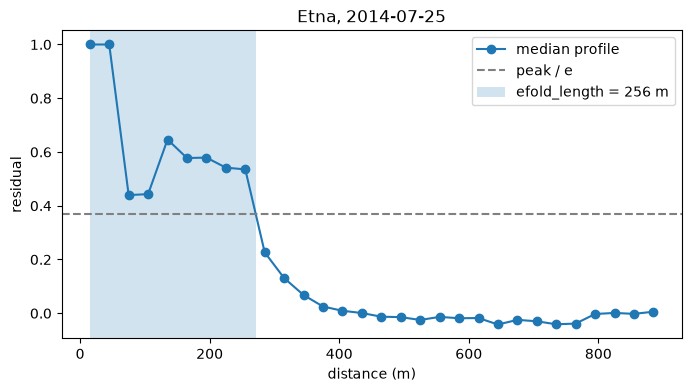

In [4]:
date = descriptors["peak"].idxmax()
row = descriptors.loc[date]
profile = volcano.scenes_median.loc[date]
radii = np.array([float(c.removesuffix("m")) for c in profile.index])
peak_radius = radii[np.nanargmax(profile.to_numpy())]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(radii, profile.to_numpy(), marker="o", label="median profile")
ax.axhline(row["peak"] / np.e, ls="--", c="gray", label="peak / e")
ax.axvspan(
    peak_radius,
    peak_radius + row["efold_length"],
    alpha=0.2,
    label=f"efold_length = {row['efold_length']:.0f} m",
)
ax.set_xlabel("distance (m)")
ax.set_ylabel("residual")
ax.set_title(f"Etna, {date:%Y-%m-%d}")
ax.legend()

`anisotropy` and `azimuth` come from a vector sum: each direction contributes a vector along its compass bearing, as long as its ray's positive peak (the maximum residual along that direction, see [rays.ipynb](rays.ipynb)). Peaks keep it about the near field: weighting by area instead would let the far field, which covers most of the disk, pick the direction. A long resultant means the heat sits on one side of the vent — e.g. a lava flow going down a flank.

Over 25 years, Etna's heat points mostly towards one side. The rose below weights every scene by its `anisotropy`, so scenes with no clear direction barely count:

Text(0.5, 1.0, 'Etna: azimuth weighted by anisotropy')

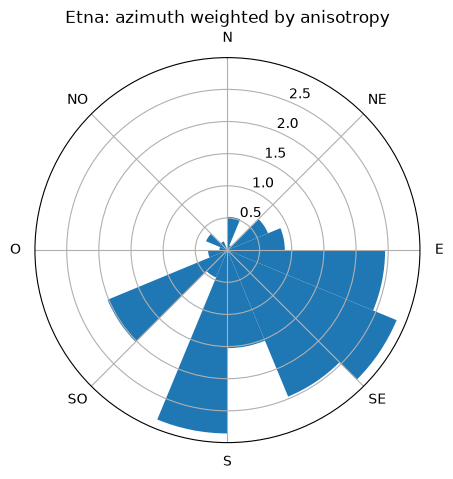

In [5]:
valid = descriptors.dropna(subset=["azimuth"])
bins = np.linspace(0, 360, 17)
counts, _ = np.histogram(
    valid["azimuth"], bins=bins, weights=valid["anisotropy"]
)

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)  # clockwise, like a compass
ax.bar(np.radians(bins[:-1]), counts, width=np.radians(22.5), align="edge")
ax.set_xticks(np.radians(np.arange(0, 360, 45)), DIRECTION_ORDER)
ax.set_title("Etna: azimuth weighted by anisotropy")

The same directional picture, scene by scene: `volcano.plot.polar()` draws every date as a polygon on a compass (each vertex is that direction's residual averaged over distance), colored by date. The dashed circle is a residual of 0.

<PolarAxes: title={'center': 'etna: residual by direction and date'}>

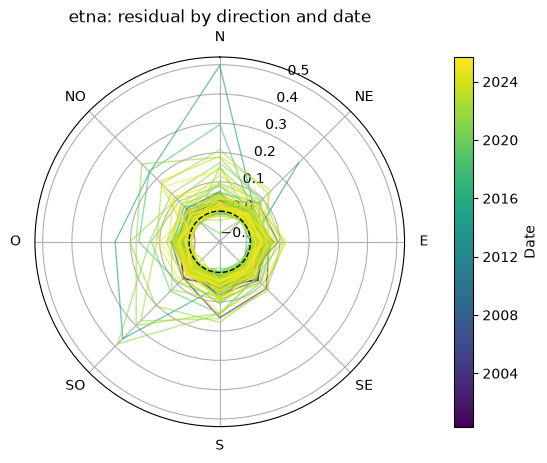

In [6]:
volcano.plot.polar()

Pass `dates` to focus on a few scenes, e.g. the five hottest by `peak`:

<PolarAxes: title={'center': 'etna: residual by direction and date'}>

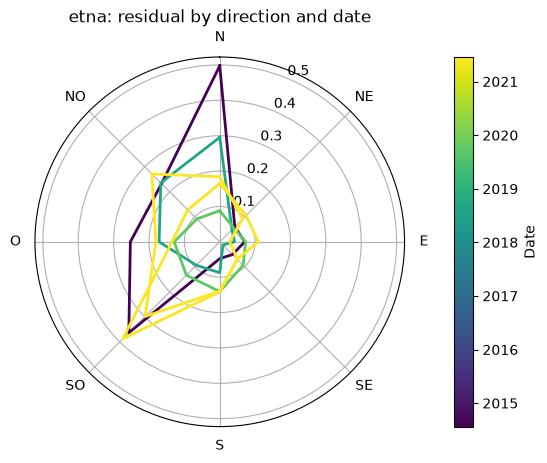

In [7]:
hottest = descriptors["peak"].nlargest(5).index
volcano.plot.polar(dates=hottest, linewidth=2, alpha=1)

And the descriptors as time series:

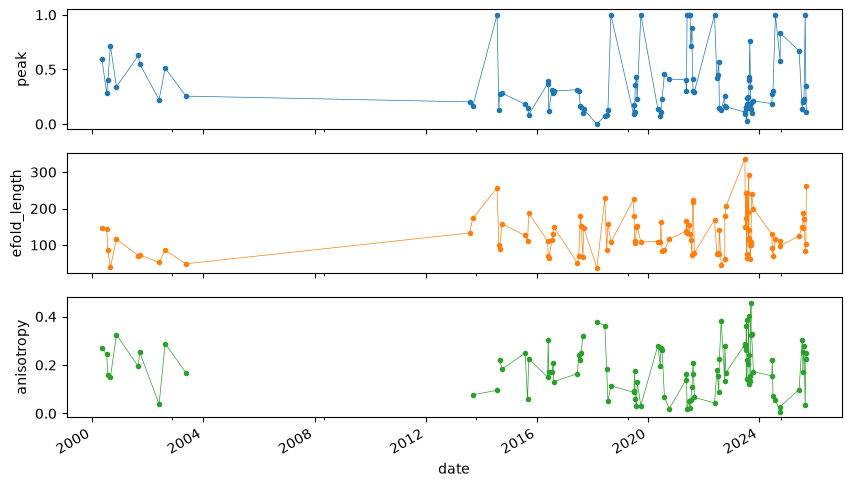

In [8]:
columns = ["peak", "efold_length", "anisotropy"]
axes = descriptors[columns].plot(
    subplots=True, figsize=(10, 6), marker=".", lw=0.5, legend=False
)
for ax, column in zip(axes, columns):
    ax.set_ylabel(column)

## How missing data is handled

Almost every scene has gaps, and they are not random: the **innermost bin (15 m) is missing in most rays**, while the rest miss only a few percent:

<Axes: xlabel='distance', ylabel='fraction missing'>

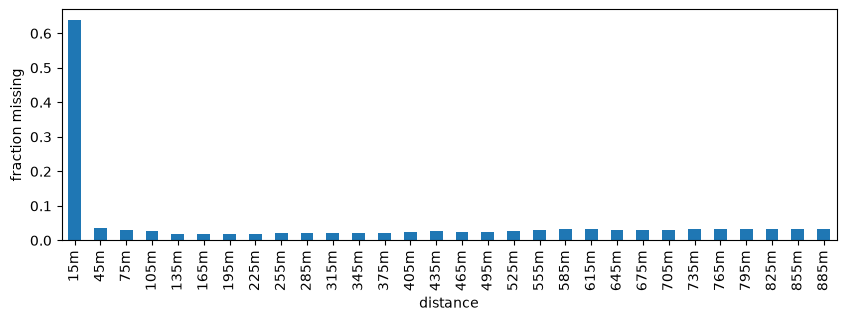

In [9]:
cube = volcano.to_scenes(as_array=True)
missing = pd.Series(
    np.isnan(cube).mean(axis=(0, 1)), index=volcano.scenes_median.columns
)
missing.plot.bar(figsize=(10, 3), ylabel="fraction missing")

If descriptors just skipped the `NaN`s, they would depend on which bins a scene happened to have, and wouldn't be comparable between scenes. So:

- **Gaps along a direction are linearly interpolated** over distance before computing anything.
- For `integrated` the edges also take the nearest available bin, so a missing 15 m bin isn't counted as zero.
- `peak` and `efold_length` **don't extrapolate**: a scene missing its 15 m bin peaks at the first bin it has. That's why `efold_length` is measured **from the peak** and not from the vent: for an exponential decay it gives the same decay length whichever bin the profile starts at. `peak` itself, however, is lower when the innermost bin is missing — unavoidable, keep it in mind.
- A scene with a **whole direction missing** gets `NaN` `anisotropy` and `azimuth` (an absent sector would bias the vector sum); `integrated` uses the mean of the other directions in its place. Use `impute()` first to fill those.

## ⚠️ Caveat 1: corrupted values (the Kadovar case)

Residuals normally live within roughly ±1. A handful of values in the bundled datasets are orders of magnitude off. Most of them are in **Kadovar**:

In [10]:
kadovar = volcanicus.datasets.load("kadovar")
df = kadovar.to_dataframe()
distances = kadovar.scenes_median.columns
values = df[distances].stack()
values.quantile([0, 0.001, 0.5, 0.999, 1]).round(2)

0.000   -1264.85
0.001      -2.62
0.500       0.00
0.999       2.04
1.000      13.31
dtype: float64

99.8% of the values are within about ±2.6, yet the minimum is −1264. These **can't be real measurements**: positive residuals saturate at exactly 1.0 (see [rays.ipynb](rays.ipynb)), and nothing physical sits a thousand times beyond that. Here they are:

In [11]:
outliers = values[values.abs() > 5]
outliers = df.loc[outliers.index.get_level_values(0), ["date", "direction"]].assign(
    distance=outliers.index.get_level_values(1), residual=outliers.values
)
outliers.sort_values("residual").head(10)

,date,direction,distance,residual
283,2018-05-27,NO,45m,-1264.8475
283,2018-05-27,NO,75m,-1096.5686
283,2018-05-27,NO,105m,-866.4164
283,2018-05-27,NO,135m,-856.0679
291,2018-07-30,NO,45m,-112.5432
291,2018-07-30,NO,75m,-97.5886
291,2018-07-30,NO,105m,-77.3248
291,2018-07-30,NO,135m,-76.1439
227,2017-08-28,NO,15m,-7.3996
227,2017-08-28,NO,45m,-5.8745


They are not isolated pixels: on 2018-05-27 the whole `NO` ray is corrupted from 45 m to 135 m (−1265 down to −856), and on 2018-07-30 the very same stretch reads −112 to −76. The other seven directions of that scene look perfectly ordinary:

In [12]:
bad_date = pd.Timestamp("2018-05-27")
(
    kadovar.to_scenes()
    .loc[bad_date]
    .unstack("direction")
    .reindex(distances)  # unstack sorts "15m" after "135m"
    .iloc[:9]
    .round(2)
)

direction,E,N,NE,NO,O,S,SE,SO
distance,,,,,,,,
15m,NaN,NaN,0.12,NaN,0.10,NaN,0.15,0.09
45m,0.08,0.21,0.05,-1264.85,0.10,0.11,0.12,0.10
75m,0.06,0.18,0.04,-1096.57,0.08,0.10,0.11,0.08
105m,0.05,0.15,0.06,-866.42,0.06,0.09,0.09,0.07
135m,0.03,0.16,0.08,-856.07,0.00,0.07,0.08,0.07
165m,0.03,0.20,0.07,NaN,-0.01,0.06,0.06,0.06
195m,0.03,0.27,0.05,NaN,-0.01,0.05,0.05,0.05
225m,0.01,0.30,0.04,0.00,0.00,0.05,0.04,0.05
255m,0.01,0.34,0.02,0.04,0.01,0.07,0.04,0.05


How much this hurts depends on the descriptor. `peak` and `efold_length` come from the **median** across directions, so one absurd direction is simply outvoted. `anisotropy` and `azimuth` use each ray's peak, which a negative glitch doesn't change. `integrated`, though, is a **sum**: a few values in the thousands, multiplied by their sector areas, wipe out the rest of the scene.

In [13]:
kadovar_desc = kadovar.scenes_descriptors()
kadovar_desc.loc[bad_date]

peak            1.107000e-01
efold_length    3.386826e+02
integrated     -1.210454e+07
anisotropy      2.006215e-01
azimuth         1.630740e+01
Name: 2018-05-27 00:00:00, dtype: float64

Text(0.5, 1.0, 'Kadovar: one corrupted ray dominates the series')

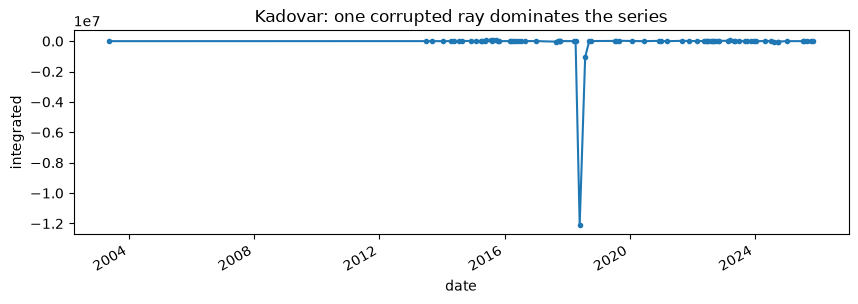

In [14]:
fig, ax = plt.subplots(figsize=(10, 3))
kadovar_desc["integrated"].plot(ax=ax, marker=".")
ax.set_ylabel("integrated")
ax.set_title("Kadovar: one corrupted ray dominates the series")

The library doesn't clean these silently, but `mask_rays()` returns a new `Volcano` with every ray holding a residual beyond ±2 (twice the saturation level) blanked out. [rays.ipynb](rays.ipynb) covers it in detail:

In [15]:
kadovar_clean = kadovar.mask_rays()

pd.DataFrame(
    {
        "raw": kadovar_desc.loc[bad_date],
        "masked": kadovar_clean.scenes_descriptors().loc[bad_date],
    }
).round(3)

,raw,masked
peak,1.110000e-01,0.111
efold_length,3.386830e+02,223.598
integrated,-1.210454e+07,20073.121
anisotropy,2.010000e-01,NaN
azimuth,1.630700e+01,NaN


Masking turns the corrupted ray into a missing one: `integrated` drops back into the normal range and `peak` doesn't change. `efold_length` does: dropping a whole direction shifts the median profile it's measured on. `anisotropy` and `azimuth` become `NaN`, as for any scene with a whole direction missing (`impute()` fills it).

Kadovar is the worst case, but not the only one. Across the 186 datasets (this takes a few seconds):

In [16]:
rows = []
for name in volcanicus.datasets.available():
    v = volcanicus.datasets.load(name)
    vals = v.to_dataframe()[v.scenes_median.columns].stack()
    big = vals[vals.abs() > 5]
    if len(big):
        rows.append(
            {"volcano": name, "n": len(big), "min": big.min(), "max": big.max()}
        )
pd.DataFrame(rows).set_index("volcano").round(1)

,n,min,max
volcano,,,
bogoslof,1,-5.0,-5.0
kadovar,26,-1264.8,13.3
karangetang,3,5.1,5.5
nyiragongo,2,-14.7,-6.7
raikoke,2,-9.1,-8.9


34 values out of ~3.4 million. Some (e.g. Nyiragongo, home to a lava lake) could conceivably be real extremes; Kadovar's −1264 cannot, and Bogoslof's suspiciously round −5.0 is worth a look too. They should be reviewed at the source.

## ⚠️ Caveat 2: `integrated` is dominated by the far field

Every bin is weighted by its area, and a ring's area grows with its radius: the 885 m ring weighs **59 times** more than the 15 m one.

Text(0, 0.5, 'share of the disk area')

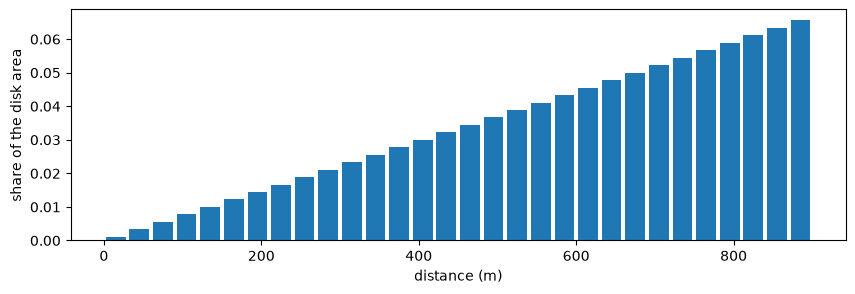

In [17]:
radii = np.array([float(c.removesuffix("m")) for c in distances])
area = 2 * np.pi * radii * np.gradient(radii)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(radii, area / area.sum(), width=25)
ax.set_xlabel("distance (m)")
ax.set_ylabel("share of the disk area")

The heat, on the other hand, is concentrated near the vent. So small residuals far from the volcano, multiplied by huge areas, weigh as much in `integrated` as the anomaly itself. Splitting Etna's integral at 300 m shows it (using the median profile, for illustration):

<Axes: xlabel='date', ylabel='residual x m²'>

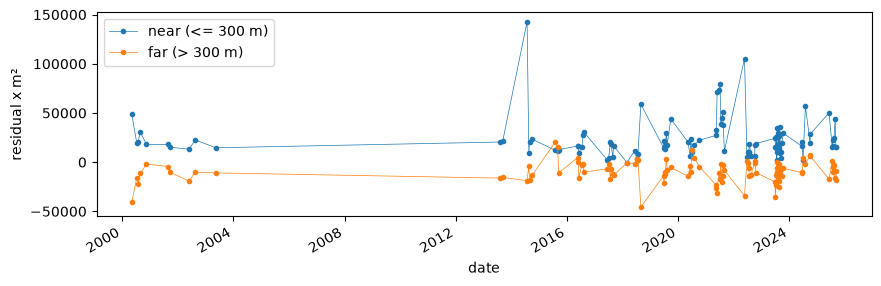

In [18]:
median = volcano.scenes_median.to_numpy()
contribution = median * area  # per bin, residual x m²
near = radii <= 300

split = pd.DataFrame(
    {
        "near (<= 300 m)": np.nansum(contribution[:, near], axis=1),
        "far (> 300 m)": np.nansum(contribution[:, ~near], axis=1),
    },
    index=volcano.scenes_median.index,
)
split.plot(figsize=(10, 3), marker=".", lw=0.5, ylabel="residual x m²")

The far field is mostly slightly **negative** (a bit colder than the background) and of the same order as the near field, so it cancels a good part of the anomaly: `integrated` ends up mixing the vent's heat with how the far surroundings compare to the background. If what you care about is the vent's anomaly, `peak` is the more direct signal, or restrict the integral to the near field as above (a near-field variant is a natural addition to the library).

## Next steps

- [scenes.ipynb](scenes.ipynb) for `to_scenes()` and `reduce_directions()`, which the descriptors are built on.
- [rays.ipynb](rays.ipynb) for the same descriptors per direction, saturation, and flagging/masking corrupted rays.
- [tutorial.ipynb](tutorial.ipynb) for the full `Volcano` API walkthrough, including `impute()`.
- [README.md](../README.md) for installation and a quick reference.